In [1]:
!pip install openpyxl

In [2]:
!pip install tensorflow

In [3]:
import pandas as pd
import numpy as np
import pandas as pd
from sklearn import model_selection
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.layers import TextVectorization
from tensorflow.keras.layers import Embedding
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM,Dense,Dropout
from tensorflow.keras.layers import Bidirectional
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import classification_report,confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import spacy
sns.set_theme(style="darkgrid")
from sklearn.model_selection import train_test_split

In [4]:
data=pd.read_excel("df_reddit_news.xlsx")

In [5]:
data.drop(columns="Unnamed: 0",inplace=True)

In [6]:
data

,text,annotation
0,Les français aiment-ils tellement se plaindre ...,1
1,"Retour en Iran, chute du régime... Ce qu’il fa...",0
2,Sébastien Lecornu a présenté sa démission à l’...,0
3,"« Ce qui tue les automobilistes, c’est l’assis...",0
4,Test : quel cadeau de Noël raté êtes-vous ? |N...,1
...,...,...
5246,Interdiction des réseaux sociaux aux moins de ...,0
5247,Fiat 500 : cet atelier italien électrifie des ...,0
5248,Affaire Epstein : une commission d’enquête par...,0
5249,Le président de SOS racisme mis en examen pour...,0


In [7]:
import sklearn
print(sklearn.__version__)

1.6.1


In [8]:
!pip install gensim

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 33.6 MB/s eta 0:00:00


In [9]:
import gensim.downloader as api
model=api.load("conceptnet-numberbatch-17-06-300")

[==================================================] 100.0% 1168.7/1168.7MB downloaded


In [10]:
from tensorflow.keras.preprocessing.text import Tokenizer

tokenizer = Tokenizer()
tokenizer.fit_on_texts(data["text"])

In [11]:
word_index = tokenizer.word_index

In [ ]:
#vocab_size = len(word_index) + 1

#print(vocab_size)

In [ ]:
#print(model)

KeyedVectors<vector_size=300, 1917247 keys>


In [12]:
embedding_dim = 300

In [13]:
import numpy as np

#embedding_matrix = np.zeros((vocab_size, embedding_dim))

In [ ]:
#for word, idx in word_index.items():

    #key = f"/c/fr/{word}"

    #if key in model:
        #embedding_matrix[idx] = model[key]

In [ ]:
#found = 0

#for word in word_index:

    #key = f"/c/fr/{word}"

    #if key in model:
        #found += 1

#print(found)
#print(len(word_index))
#print(found / len(word_index))

In [ ]:
#X=tokenizer.texts_to_sequences(data["text"])

In [14]:
from tensorflow.keras.preprocessing.sequence import pad_sequences

In [ ]:
#X=pad_sequences(
    #X,
    #maxlen=100,
    #padding="post"
#)

In [ ]:
#embedding_layer=Embedding(
    #input_dim=vocab_size,
    #output_dim=embedding_dim,
    #weights=[embedding_matrix],
    #trainable=False
#)

Entrainement du modèle LSTM

Shuffle les données afin d'éviter d'avoir les reddits se suivant et les journaux se suivant

In [15]:
data = data.sample(frac=1, random_state=1).reset_index(drop=True)

In [16]:
texts=data["text"].astype(str).to_list()
labels=data["annotation"].values

In [17]:
X_train_texts,X_test_texts,y_train,y_test=train_test_split(
    texts,
    labels,
    test_size=0.20,
    random_state=1,
    stratify=labels
)

In [18]:
tokenizer.fit_on_texts(X_train_texts)

X_train_seq=tokenizer.texts_to_sequences(X_train_texts)
X_test_seq=tokenizer.texts_to_sequences(X_test_texts)

In [19]:
max_len=100
X_train=pad_sequences(X_train_seq,maxlen=max_len)
X_test=pad_sequences(X_test_seq,maxlen=max_len)

In [20]:
import numpy as np

vocab_size = len(tokenizer.word_index) + 1
embedding_dim = 300

embedding_matrix = np.zeros((vocab_size, embedding_dim))

for word, idx in tokenizer.word_index.items():

    key_en = f"/c/en/{word}"
    key_fr = f"/c/fr/{word}"

    if key_en in model:
        embedding_matrix[idx] = model[key_en]
    elif key_fr in model:
        embedding_matrix[idx] = model[key_fr]

In [21]:
model_nn=Sequential()

model_nn.add(
    Embedding(
        input_dim=vocab_size,
        output_dim=embedding_dim,
        weights=[embedding_matrix],
        trainable=False
    )
)

model_nn.add(Bidirectional(LSTM(128)))
model_nn.add(Dropout(0.3))

model_nn.add(Dense(1,activation="sigmoid"))

In [22]:
model_nn.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

In [23]:
early_stop=EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

In [24]:
history = model_nn.fit(
    X_train,
    y_train,
    validation_split=0.2,
    epochs=20,
    batch_size=32,
    callbacks=[early_stop]
)

Epoch 1/20
105/105 ━━━━━━━━━━━━━━━━━━━━ 9s 20ms/step - accuracy: 0.5756 - loss: 0.6811 - val_accuracy: 0.6357 - val_loss: 0.6667
Epoch 2/20
105/105 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.6241 - loss: 0.6521 - val_accuracy: 0.6357 - val_loss: 0.6323
Epoch 3/20
105/105 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.6643 - loss: 0.6118 - val_accuracy: 0.6607 - val_loss: 0.6150
Epoch 4/20
105/105 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.6705 - loss: 0.5950 - val_accuracy: 0.6393 - val_loss: 0.6176
Epoch 5/20
105/105 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.7161 - loss: 0.5586 - val_accuracy: 0.7190 - val_loss: 0.5479
Epoch 6/20
105/105 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.7420 - loss: 0.5165 - val_accuracy: 0.7405 - val_loss: 0.5375
Epoch 7/20
105/105 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - accuracy: 0.7628 - loss: 0.4795 - val_accuracy: 0.6929 - val_loss: 0.5759
Epoch 8/20
105/105 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - accuracy: 0.7804 - loss: 0.4540 - val_accu

In [25]:
print(history.history.keys())

dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss'])


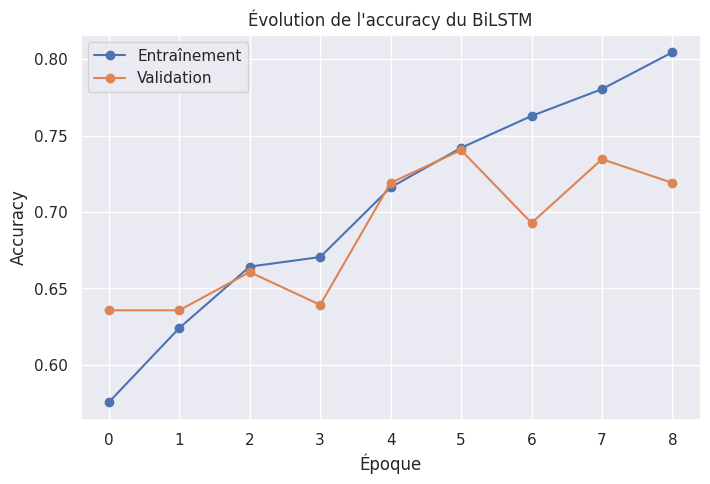

In [26]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.plot(
    history.history['accuracy'],
    marker='o',
    label='Entraînement'
)

plt.plot(
    history.history['val_accuracy'],
    marker='o',
    label='Validation'
)

plt.xlabel("Époque")
plt.ylabel("Accuracy")
plt.title("Évolution de l'accuracy du BiLSTM")
plt.legend()
plt.grid(True)

plt.show()

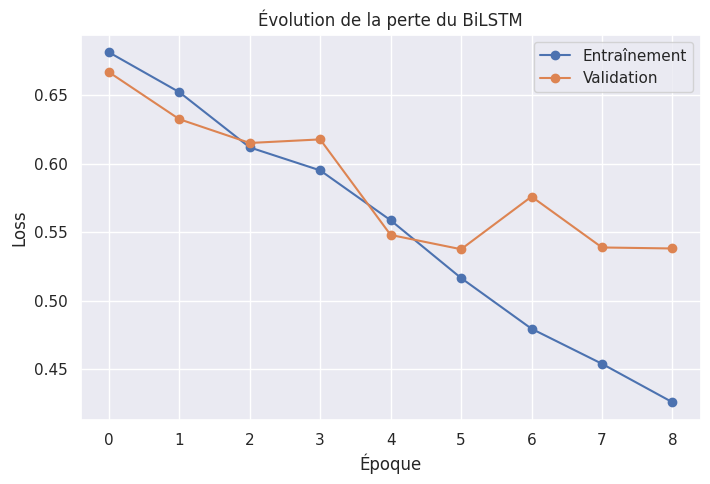

In [27]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.plot(
    history.history['loss'],
    marker='o',
    label='Entraînement'
)

plt.plot(
    history.history['val_loss'],
    marker='o',
    label='Validation'
)

plt.xlabel("Époque")
plt.ylabel("Loss")
plt.title("Évolution de la perte du BiLSTM")
plt.legend()
plt.grid(True)

plt.show()

In [28]:
y_pred=model_nn.evaluate(X_test, y_test)

33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - accuracy: 0.6936 - loss: 0.5806


In [29]:
y_pred = model_nn.predict(X_test)
y_pred = (y_pred > 0.5).astype(int).ravel()

33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step


In [30]:
from sklearn.metrics import classification_report
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.72      0.75      0.73       590
           1       0.66      0.62      0.64       461

    accuracy                           0.69      1051
   macro avg       0.69      0.69      0.69      1051
weighted avg       0.69      0.69      0.69      1051



In [31]:
import pandas as pd

results = pd.DataFrame({
    "texte": X_test_texts,
    "y_true": y_test,
    "y_pred": y_pred
})

In [32]:
results.to_csv("results_lstm_test.csv")
results

,texte,y_true,y_pred
0,"Au RN, une attraction inavouée pour le trumpis...",1,0
1,"A La Réunion, l’éruption du piton de la Fourna...",0,0
2,"""La prison, c'est quelque chose d'assez diffic...",0,1
3,Municipales 2026 : la droite espère toujours u...,0,0
4,"« Ce qui tue les automobilistes, c’est l’assis...",1,1
...,...,...,...
1046,Attentat lors d’une projection du film de BHL ...,1,0
1047,Quand Clemenceau était «le premier des flics» ...,0,0
1048,Municipales à Paris : Emmanuel Grégoire toujou...,0,0
1049,« Je ne suis pas un meurtrier » : l’automobili...,0,0


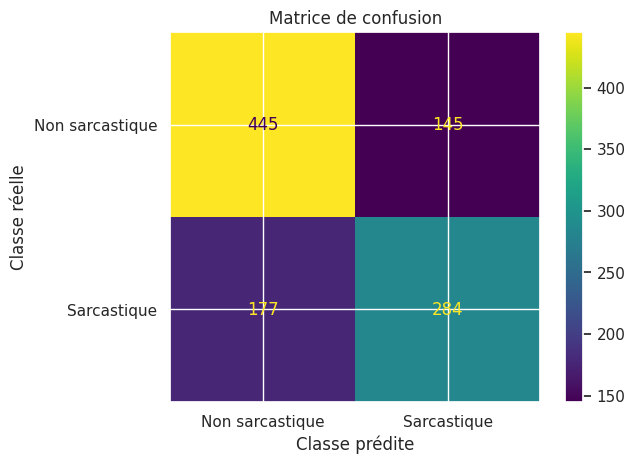

In [33]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Calcul de la matrice de confusion
cm = confusion_matrix(y_test, y_pred)

# Affichage
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Non sarcastique", "Sarcastique"]
)

disp.plot(values_format="d")

plt.title("Matrice de confusion")
plt.xlabel("Classe prédite")
plt.ylabel("Classe réelle")
plt.show()